# Sumativa 3: Preparación e imputación del ingreso mensual

**Asignatura:** Estadística Computacional  
**Integrantes:** Hernán Saavedra, Lenin Morales y Rodrigo Gómez  
**Responsable de este notebook:** Hernán Saavedra  
**Dataset:** IBM HR Employee Attrition

## Objetivo

Comparar eliminación de registros, imputación por mediana e imputación
mediante regresión lineal múltiple para preparar los datos del
modelamiento logístico final.

## Continuidad con S1, S2 y Formativa 2

El dataset original utilizado en S1 y S2 no presentó valores faltantes.
Siguiendo la indicación docente, en Formativa 2 se ocultaron 147 valores
de MonthlyIncome (10 %) mediante un mecanismo MCAR con semilla 42.

Se reutilizan esa versión, el respaldo de los valores ocultados y la
partición estratificada por Attrition: 1.029 registros de entrenamiento
y 441 de prueba. No se generan nuevos faltantes ni una nueva partición.

Las correlaciones y los análisis de robustez de S1 y S2 fundamentarán
la elección de predictores para imputar el ingreso. Los modelos de
imputación se ajustarán exclusivamente con entrenamiento, sin utilizar
Attrition como predictor.

Los valores ocultados se reservarán para evaluar el error de imputación.
Los datos son sintéticos y las conclusiones tienen finalidad académica.

In [13]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.impute import SimpleImputer

SEMILLA = 42

RAIZ = next(
    (
        carpeta
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (
            carpeta / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
        ).is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

DIRECTORIO_F2 = RAIZ / "Formativa2"
DIRECTORIO_S2 = RAIZ / "S2"
DIRECTORIO_S3 = RAIZ / "S3"

for nombre in ["datos", "resultados", "figuras", "docs"]:
    (DIRECTORIO_S3 / nombre).mkdir(parents=True, exist_ok=True)

archivos_requeridos = [
    DIRECTORIO_F2 / "datos" / "IBM_HR_MCAR.csv",
    DIRECTORIO_F2 / "datos" / "valores_ocultados_ingreso.csv",
    DIRECTORIO_F2 / "datos" / "particion_70_30.csv",
    DIRECTORIO_S2 / "resultados" / "S2_reporte_validado_S3.json",
]

for ruta in archivos_requeridos:
    if not ruta.is_file():
        raise FileNotFoundError(
            f"Falta un insumo previo: {ruta.relative_to(RAIZ)}"
        )

print("Python:", sys.version.split()[0])
print("Insumos de F2 y S2 encontrados.")
print("Entorno preparado para Sumativa 3.")

Python: 3.14.2
Insumos de F2 y S2 encontrados.
Entorno preparado para Sumativa 3.


## 1. Recuperación de datos y partición de Formativa 2

Se carga la versión MCAR guardada en F2 y se comprueba que únicamente
MonthlyIncome presenta faltantes. Se verifican los identificadores y
el respaldo contra el dataset original.

La asignación a entrenamiento y prueba se recupera del archivo de
partición. El dataset original y los valores ocultados se mantienen
separados de los datos empleados para ajustar la imputación.

In [14]:
df_original = pd.read_csv(
    RAIZ / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
).set_index("EmployeeNumber")

df_mcar = pd.read_csv(
    DIRECTORIO_F2 / "datos" / "IBM_HR_MCAR.csv"
).set_index("EmployeeNumber")

valores_ocultados = pd.read_csv(
    DIRECTORIO_F2 / "datos" / "valores_ocultados_ingreso.csv"
).set_index("EmployeeNumber")

particion = pd.read_csv(
    DIRECTORIO_F2 / "datos" / "particion_70_30.csv"
).set_index("EmployeeNumber")

reporte_s2 = json.loads(
    (
        DIRECTORIO_S2 / "resultados" / "S2_reporte_validado_S3.json"
    ).read_text(encoding="utf-8")
)

# Verificar que se conserva la versión MCAR de F2.
assert df_mcar.index.is_unique
assert valores_ocultados.index.is_unique
assert particion.index.is_unique
assert set(particion.index) == set(df_mcar.index)
assert set(particion["Conjunto"]) == {"Entrenamiento", "Prueba"}

assert df_mcar["MonthlyIncome"].isna().sum() == 147
assert df_mcar.isna().sum().sum() == 147

ids_ocultados = df_mcar.index[df_mcar["MonthlyIncome"].isna()]
assert set(ids_ocultados) == set(valores_ocultados.index)

pd.testing.assert_frame_equal(
    df_mcar.drop(columns="MonthlyIncome"),
    df_original.drop(columns="MonthlyIncome"),
)

np.testing.assert_allclose(
    valores_ocultados["MonthlyIncome"],
    df_original.loc[valores_ocultados.index, "MonthlyIncome"],
)

# Recuperar la asignación existente, sin sortear otra partición.
train = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Entrenamiento"]
].copy()

test = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Prueba"]
].copy()

assert len(train) == 1029 and len(test) == 441
assert set(train.index).isdisjoint(test.index)

resumen_datos = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Registros": [len(train), len(test)],
    "Ingresos faltantes": [
        train["MonthlyIncome"].isna().sum(),
        test["MonthlyIncome"].isna().sum(),
    ],
    "Salidas": [
        train["Attrition"].eq("Yes").sum(),
        test["Attrition"].eq("Yes").sum(),
    ],
})

display(resumen_datos)
print("Partición de F2 recuperada y respaldo verificado.")
print("Reporte de resultados validados de S2 cargado.")

,Conjunto,Registros,Ingresos faltantes,Salidas
0,Entrenamiento,1029,96,166
1,Prueba,441,51,71


Partición de F2 recuperada y respaldo verificado.
Reporte de resultados validados de S2 cargado.


## 2. Predictores para la imputación del ingreso

Se seleccionan tres variables numéricas disponibles sin faltantes:

| Predictor | Fundamento |
|-----------|------------|
| TotalWorkingYears | En S2, su correlación de Spearman con MonthlyIncome fue aproximadamente 0,710, con IC bootstrap BCa del 95 % [0,679; 0,739]. |
| Age | En S1 se observó una relación positiva con ingreso. Su relación con experiencia laboral fue validada en S2. |
| YearsAtCompany | En S1 se observó una relación positiva con ingreso. Su relación con experiencia laboral también fue validada en S2. |

Los intervalos de S2 respaldan relaciones específicas entre variables;
no implican que todas las correlaciones con ingreso hayan sido validadas.

Como los tres predictores están relacionados, se revisará su VIF antes
de interpretar la regresión. La utilidad para imputar se evaluará con
predicciones y diagnósticos, no únicamente mediante correlaciones.

MonthlyIncome será la respuesta de la regresión lineal. Attrition y
EmployeeNumber no se utilizarán como predictores. El ajuste empleará
solo registros de entrenamiento con ingreso observado.

In [15]:
PREDICTORES_IMPUTACION = [
    "TotalWorkingYears",
    "Age",
    "YearsAtCompany",
]

# Para ajustar la imputación, usar exclusivamente ingresos observados
# del entrenamiento y predictores completos.
train_observado = train.dropna(
    subset=["MonthlyIncome", *PREDICTORES_IMPUTACION]
).copy()

assert train[PREDICTORES_IMPUTACION].notna().all().all()
assert test[PREDICTORES_IMPUTACION].notna().all().all()
assert len(train_observado) == 933

X_imputacion = train_observado[PREDICTORES_IMPUTACION].astype(float)
y_imputacion = train_observado["MonthlyIncome"].astype(float)

print("Predictores:", PREDICTORES_IMPUTACION)
print("Registros disponibles para ajustar:", len(train_observado))
print("Ingresos por imputar en entrenamiento:",
      train["MonthlyIncome"].isna().sum())
print("Ingresos por imputar en prueba:",
      test["MonthlyIncome"].isna().sum())

print("\nCorrelaciones de Pearson en entrenamiento observado:")
display(
    train_observado[
        ["MonthlyIncome", *PREDICTORES_IMPUTACION]
    ].corr().round(3)
)

Predictores: ['TotalWorkingYears', 'Age', 'YearsAtCompany']
Registros disponibles para ajustar: 933
Ingresos por imputar en entrenamiento: 96
Ingresos por imputar en prueba: 51

Correlaciones de Pearson en entrenamiento observado:


,MonthlyIncome,TotalWorkingYears,Age,YearsAtCompany
MonthlyIncome,1.000,0.776,0.514,0.496
TotalWorkingYears,0.776,1.000,0.686,0.615
Age,0.514,0.686,1.000,0.299
YearsAtCompany,0.496,0.615,0.299,1.000


## 3. Ajuste de la regresión lineal múltiple

Se estima MonthlyIncome mediante experiencia laboral total, edad y
antigüedad en la empresa, incluyendo intercepto. El ajuste utiliza
exclusivamente los 933 registros de entrenamiento con ingreso observado.

Se calcula el VIF para evaluar la redundancia entre predictores.
Los coeficientes expresan asociaciones ajustadas con el ingreso y
no representan efectos causales.

El resumen del ajuste describe el comportamiento dentro de estos
registros. Posteriormente se evaluarán los residuos y el error
predictivo antes de utilizar el modelo para imputar.

In [16]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_imputacion_const = sm.add_constant(
    X_imputacion,
    has_constant="add",
)

# Calcular VIF con intercepto, pero mostrar solo los predictores.
matriz_vif = X_imputacion_const.to_numpy(dtype=float)

vif_imputacion = pd.DataFrame({
    "Variable": X_imputacion_const.columns,
    "VIF": [
        variance_inflation_factor(matriz_vif, i)
        for i in range(matriz_vif.shape[1])
    ],
})

vif_imputacion = vif_imputacion.loc[
    vif_imputacion["Variable"] != "const"
].reset_index(drop=True)

display(vif_imputacion.round(3))

# Ajustar por mínimos cuadrados ordinarios.
modelo_ingreso = sm.OLS(
    y_imputacion,
    X_imputacion_const,
).fit()

print(modelo_ingreso.summary())

vif_imputacion.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_vif.csv",
    index=False,
)

tabla_coeficientes_ingreso = pd.DataFrame({
    "Coeficiente": modelo_ingreso.params,
    "Error estandar": modelo_ingreso.bse,
    "Valor p": modelo_ingreso.pvalues,
    "IC95 inferior": modelo_ingreso.conf_int()[0],
    "IC95 superior": modelo_ingreso.conf_int()[1],
})

tabla_coeficientes_ingreso.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_coeficientes.csv",
    index_label="Termino",
)

print("\nResultados del ajuste guardados.")

,Variable,VIF
0,TotalWorkingYears,2.897
1,Age,1.980
2,YearsAtCompany,1.684


                            OLS Regression Results                            
Dep. Variable:          MonthlyIncome   R-squared:                       0.604
Model:                            OLS   Adj. R-squared:                  0.603
Method:                 Least Squares   F-statistic:                     472.1
Date:                Sat, 24 Oct 2026   Prob (F-statistic):          2.90e-186
Time:                        22:21:17   Log-Likelihood:                -8761.0
No. Observations:                 933   AIC:                         1.753e+04
Df Residuals:                     929   BIC:                         1.755e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const              1673.1323    445.95

## 4. Diagnóstico de residuos

Se examinan residuos frente a valores ajustados para detectar patrones
de falta de linealidad o cambios de dispersión, y un gráfico Q-Q para
examinar desviaciones respecto de la normalidad.

La prueba de Breusch-Pagan complementa la evaluación de
heterocedasticidad. Su hipótesis nula es varianza constante de los
errores, bajo las condiciones de la prueba.

La normalidad de los errores no es necesaria para calcular predicciones
por mínimos cuadrados, pero sus desviaciones y la heterocedasticidad
afectan la interpretación de la inferencia clásica. Estos diagnósticos
no sustituyen la evaluación del error predictivo.

La independencia no puede confirmarse únicamente con los residuos:
se mantiene como supuesto de trabajo para estos registros sintéticos.

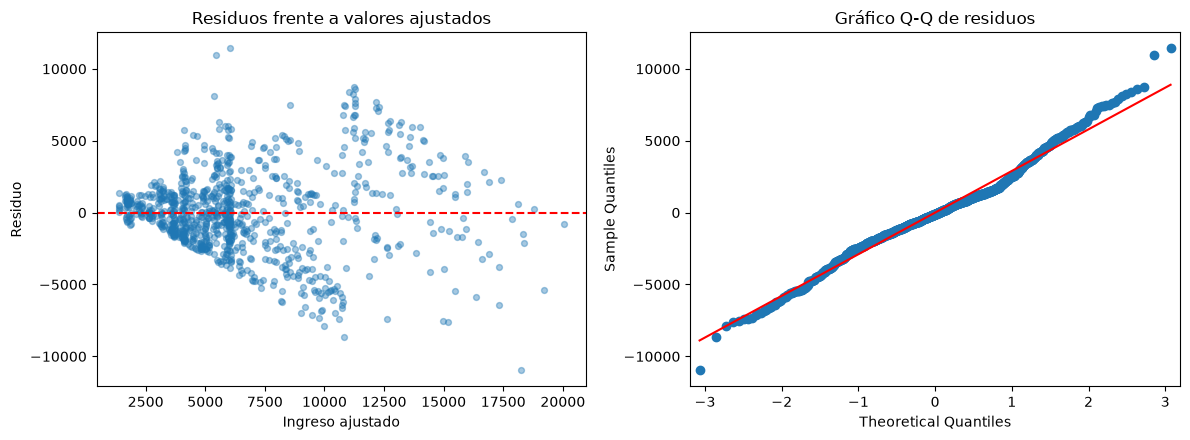

,Prueba,Estadistico LM,Valor p LM,Estadistico F,Valor p F
0,Breusch-Pagan,183.909784,1.262068e-39,76.02653,5.579882e-44


Ingresos ajustados negativos: 0


In [17]:
from statsmodels.stats.diagnostic import het_breuschpagan

ajustados = modelo_ingreso.fittedvalues
residuos = modelo_ingreso.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].scatter(ajustados, residuos, alpha=0.4, s=18)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(
    xlabel="Ingreso ajustado",
    ylabel="Residuo",
    title="Residuos frente a valores ajustados",
)

sm.qqplot(residuos, line="s", ax=axes[1])
axes[1].set_title("Gráfico Q-Q de residuos")

fig.tight_layout()
fig.savefig(
    DIRECTORIO_S3 / "figuras" / "hernan_imputacion_residuos.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

lm, p_lm, estadistico_f, p_f = het_breuschpagan(
    residuos,
    X_imputacion_const,
)

diagnostico_bp = pd.DataFrame({
    "Prueba": ["Breusch-Pagan"],
    "Estadistico LM": [lm],
    "Valor p LM": [p_lm],
    "Estadistico F": [estadistico_f],
    "Valor p F": [p_f],
})

diagnostico_bp.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_breusch_pagan.csv",
    index=False,
)

display(diagnostico_bp)

print(
    "Ingresos ajustados negativos:",
    int((ajustados < 0).sum()),
)

## 5. Evaluación predictiva dentro del entrenamiento

La prueba de Breusch-Pagan aporta evidencia de heterocedasticidad.
Por ello, la inferencia clásica requiere cautela; se complementará
con errores estándar robustos.

Se compara la imputación por regresión con la mediana mediante
validación cruzada de cinco pliegues sobre los 933 registros de
entrenamiento con ingreso observado.

En cada pliegue, la regresión y la mediana se ajustan únicamente con
los otros cuatro pliegues. Se calculan MAE y RMSE sobre predicciones
fuera del ajuste. Valores menores indican menor error.

Los registros de prueba y los valores artificialmente ocultados no
intervienen en esta comparación.

In [18]:
from sklearn.model_selection import KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA,
)

pred_cv_regresion = np.full(len(y_imputacion), np.nan)
pred_cv_mediana = np.full(len(y_imputacion), np.nan)

for indices_ajuste, indices_validacion in cv.split(X_imputacion):
    X_ajuste = X_imputacion.iloc[indices_ajuste]
    y_ajuste = y_imputacion.iloc[indices_ajuste]
    X_validacion = X_imputacion.iloc[indices_validacion]

    modelo_pliegue = sm.OLS(
        y_ajuste,
        sm.add_constant(X_ajuste, has_constant="add"),
    ).fit()

    pred_cv_regresion[indices_validacion] = modelo_pliegue.predict(
        sm.add_constant(X_validacion, has_constant="add")
    )

    pred_cv_mediana[indices_validacion] = y_ajuste.median()

assert np.isfinite(pred_cv_regresion).all()
assert np.isfinite(pred_cv_mediana).all()

comparacion_cv = []

for nombre, predicciones in [
    ("Mediana", pred_cv_mediana),
    ("Regresion", pred_cv_regresion),
]:
    errores = y_imputacion.to_numpy() - predicciones

    comparacion_cv.append({
        "Estrategia": nombre,
        "Registros evaluados": len(errores),
        "MAE": np.mean(np.abs(errores)),
        "RMSE": np.sqrt(np.mean(errores ** 2)),
    })

comparacion_cv = pd.DataFrame(comparacion_cv)

comparacion_cv.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_validacion_cruzada.csv",
    index=False,
)

pd.DataFrame({
    "Ingreso observado": y_imputacion,
    "Prediccion CV mediana": pred_cv_mediana,
    "Prediccion CV regresion": pred_cv_regresion,
}).to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_predicciones_cv.csv",
    index_label="EmployeeNumber",
)

display(comparacion_cv.round(2))

,Estrategia,Registros evaluados,MAE,RMSE
0,Mediana,933,3308.30,4848.16
1,Regresion,933,2174.84,2923.40


## 6. Inferencia robusta y resultados de validación

En validación cruzada, la regresión obtuvo MAE de 2.174,84 y RMSE
de 2.923,40, frente a 3.308,30 y 4.848,16 de la mediana.
Esto representa reducciones aproximadas de 34,3 % y 39,7 %,
respectivamente, dentro del entrenamiento observado.

Dada la heterocedasticidad detectada, se calculan errores estándar
robustos HC3 e intervalos del 95 %. Este ajuste modifica la inferencia,
pero conserva los coeficientes y las predicciones de mínimos cuadrados.
No corrige posibles errores de especificación ni incorpora toda la
incertidumbre de la imputación.

In [19]:
resultado_hc3 = modelo_ingreso.get_robustcov_results(cov_type="HC3")
intervalos_hc3 = np.asarray(resultado_hc3.conf_int(alpha=0.05))

tabla_hc3 = pd.DataFrame({
    "Variable": modelo_ingreso.model.exog_names,
    "Coeficiente": np.asarray(resultado_hc3.params),
    "Error estandar HC3": np.asarray(resultado_hc3.bse),
    "Valor p HC3": np.asarray(resultado_hc3.pvalues),
    "IC95 inferior HC3": intervalos_hc3[:, 0],
    "IC95 superior HC3": intervalos_hc3[:, 1],
})

tabla_hc3.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_imputacion_coeficientes_hc3.csv",
    index=False,
)

display(tabla_hc3.round(4))
print("Inferencia robusta HC3 calculada y guardada.")

,Variable,Coeficiente,Error estandar HC3,Valor p HC3,IC95 inferior HC3,IC95 superior HC3
0,const,1673.1323,367.7867,0.0000,951.3431,2394.9214
1,TotalWorkingYears,467.9710,27.2443,0.0000,414.5035,521.4385
2,Age,-15.3636,12.3724,0.2146,-39.6447,8.9175
3,YearsAtCompany,17.8908,30.1965,0.5537,-41.3706,77.1521


Inferencia robusta HC3 calculada y guardada.


## 7. Construcción de las tres estrategias de faltantes

Se conserva la asignación original de entrenamiento y prueba:

- **Eliminación:** se excluyen los registros con ingreso faltante.
- **Mediana:** se rellenan los faltantes de ambos conjuntos con la
  mediana del entrenamiento observado.
- **Regresión:** se rellenan los faltantes con predicciones del modelo
  ajustado exclusivamente sobre entrenamiento observado.

Los ingresos observados se conservan. No se utilizan los valores
ocultados ni Attrition para calcular las imputaciones. Se comprueba
que las predicciones de ingreso sean positivas antes de aplicarlas.

In [20]:
# 1. Eliminación.
train_eliminacion = train.dropna(subset=["MonthlyIncome"]).copy()
test_eliminacion = test.dropna(subset=["MonthlyIncome"]).copy()

# 2. Mediana: ajustar solo con entrenamiento.
imputador_mediana = SimpleImputer(strategy="median")

train_mediana = train.copy()
test_mediana = test.copy()

train_mediana["MonthlyIncome"] = imputador_mediana.fit_transform(
    train[["MonthlyIncome"]]
).ravel()

test_mediana["MonthlyIncome"] = imputador_mediana.transform(
    test[["MonthlyIncome"]]
).ravel()

# 3. Regresión: aplicar el modelo ya ajustado.
train_regresion = train.copy()
test_regresion = test.copy()

for datos in [train_regresion, test_regresion]:
    faltantes = datos["MonthlyIncome"].isna()

    if faltantes.any():
        X_faltantes = datos.loc[
            faltantes, PREDICTORES_IMPUTACION
        ].astype(float)

        predicciones = modelo_ingreso.predict(
            sm.add_constant(X_faltantes, has_constant="add")
        )

        if not np.isfinite(predicciones).all():
            raise ValueError("Se generaron predicciones no finitas.")

        if (predicciones <= 0).any():
            raise ValueError(
                "Hay ingresos predichos no positivos. "
                "Revisar el modelo antes de imputar."
            )

        datos.loc[faltantes, "MonthlyIncome"] = predicciones

estrategias = {
    "eliminacion": {
        "train": train_eliminacion,
        "test": test_eliminacion,
    },
    "mediana": {
        "train": train_mediana,
        "test": test_mediana,
    },
    "regresion": {
        "train": train_regresion,
        "test": test_regresion,
    },
}

resumen_estrategias = []

for nombre, conjuntos in estrategias.items():
    for conjunto, datos in conjuntos.items():
        assert not datos.isna().any().any()

        # Verificar que ningún ingreso observado fue modificado.
        base = train if conjunto == "train" else test
        ids_observados = base.index[base["MonthlyIncome"].notna()]

        np.testing.assert_allclose(
            datos.loc[ids_observados, "MonthlyIncome"],
            base.loc[ids_observados, "MonthlyIncome"],
        )

        datos.to_csv(
            DIRECTORIO_S3 / "datos" / f"{nombre}_{conjunto}.csv",
            index_label="EmployeeNumber",
        )

        resumen_estrategias.append({
            "Estrategia": nombre,
            "Conjunto": conjunto,
            "Registros": len(datos),
            "Ingresos faltantes": datos["MonthlyIncome"].isna().sum(),
        })

resumen_estrategias = pd.DataFrame(resumen_estrategias)

resumen_estrategias.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_resumen_estrategias.csv",
    index=False,
)

display(resumen_estrategias)
print("Mediana utilizada:", float(imputador_mediana.statistics_[0]))

,Estrategia,Conjunto,Registros,Ingresos faltantes
0,eliminacion,train,933,0
1,eliminacion,test,390,0
2,mediana,train,1029,0
3,mediana,test,441,0
4,regresion,train,1029,0
5,regresion,test,441,0


Mediana utilizada: 5067.0


## 8. Error de imputación frente a los valores ocultados

Como los faltantes fueron generados artificialmente, se conocen los
ingresos verdaderos de los 147 registros afectados. Se calculan MAE,
RMSE y sesgo medio para mediana y regresión, separados por conjunto.

El sesgo se define como ingreso imputado menos ingreso verdadero.
Un valor positivo indica sobreestimación media y uno negativo,
subestimación.

La eliminación no produce valores imputados: su error de imputación
no aplica. Su impacto se evalúa mediante la pérdida de observaciones.

Los valores ocultados no participaron en el ajuste. La selección
metodológica se fundamentará en entrenamiento; los errores de prueba
se reservan para la evaluación final.

In [21]:
resultados_error = []
detalle_error = []

for nombre in ["mediana", "regresion"]:
    for conjunto in ["train", "test"]:
        datos = estrategias[nombre][conjunto]

        ids_evaluar = datos.index[
            datos.index.isin(valores_ocultados.index)
        ]

        verdaderos = valores_ocultados.loc[
            ids_evaluar, "MonthlyIncome"
        ].to_numpy()

        imputados = datos.loc[
            ids_evaluar, "MonthlyIncome"
        ].to_numpy()

        errores = imputados - verdaderos

        resultados_error.append({
            "Estrategia": nombre,
            "Conjunto": conjunto,
            "Valores evaluados": len(ids_evaluar),
            "MAE": np.mean(np.abs(errores)),
            "RMSE": np.sqrt(np.mean(errores ** 2)),
            "Sesgo medio": np.mean(errores),
        })

        detalle_error.append(pd.DataFrame({
            "EmployeeNumber": ids_evaluar,
            "Estrategia": nombre,
            "Conjunto": conjunto,
            "Ingreso verdadero": verdaderos,
            "Ingreso imputado": imputados,
            "Error": errores,
        }))

errores_imputacion = pd.DataFrame(resultados_error)

errores_imputacion.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_error_imputacion.csv",
    index=False,
)

pd.concat(detalle_error, ignore_index=True).to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_error_imputacion_detalle.csv",
    index=False,
)

# Mostrar por ahora solo entrenamiento.
display(
    errores_imputacion.loc[
        errores_imputacion["Conjunto"] == "train"
    ].round(2)
)

print("Errores de ambos conjuntos guardados para el informe final.")

,Estrategia,Conjunto,Valores evaluados,MAE,RMSE,Sesgo medio
0,mediana,train,96,3322.04,4859.04,-1317.79
2,regresion,train,96,2260.28,3316.88,-208.92


Errores de ambos conjuntos guardados para el informe final.


## 9. Distribución del ingreso y preservación de correlaciones

Se comparan las tres estrategias mediante medidas descriptivas del
ingreso y correlaciones de Spearman con experiencia, edad y antigüedad.

Como referencia de evaluación se utiliza el entrenamiento original
completo, cuyos ingresos verdaderos conocemos por tratarse de un
ejercicio con faltantes artificiales. Esta referencia no participa
en el ajuste de los imputadores.

La mediana puede producir una concentración artificial de valores.
La imputación por regresión puede reducir la variabilidad residual
y reforzar relaciones con sus propios predictores. Por ello, un
menor error de imputación no garantiza preservar toda la distribución.

La eliminación cambia la composición y el tamaño de la muestra;
sus diferencias no se atribuyen únicamente al método de imputación.

In [22]:
referencia_train = df_original.loc[train.index].copy()

conjuntos_comparacion = {
    "Referencia original": referencia_train,
    "Eliminacion": train_eliminacion,
    "Mediana": train_mediana,
    "Regresion": train_regresion,
}

filas_distribucion = []
filas_correlacion = []

for nombre, datos in conjuntos_comparacion.items():
    ingreso = datos["MonthlyIncome"]

    filas_distribucion.append({
        "Estrategia": nombre,
        "Registros": len(datos),
        "Media": ingreso.mean(),
        "Mediana": ingreso.median(),
        "Desviacion estandar": ingreso.std(),
        "Q1": ingreso.quantile(0.25),
        "Q3": ingreso.quantile(0.75),
        "Asimetria": ingreso.skew(),
    })

    correlaciones = datos[
        ["MonthlyIncome", *PREDICTORES_IMPUTACION]
    ].corr(method="spearman")

    filas_correlacion.append({
        "Estrategia": nombre,
        **{
            variable: correlaciones.loc["MonthlyIncome", variable]
            for variable in PREDICTORES_IMPUTACION
        },
    })

comparacion_distribucion = pd.DataFrame(filas_distribucion)
comparacion_correlaciones = pd.DataFrame(filas_correlacion)

comparacion_distribucion.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_distribucion_ingreso.csv",
    index=False,
)

comparacion_correlaciones.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_correlaciones_ingreso.csv",
    index=False,
)

print("Distribución del ingreso en entrenamiento:")
display(comparacion_distribucion.round(2))

print("Correlaciones de Spearman con ingreso en entrenamiento:")
display(comparacion_correlaciones.round(3))

Distribución del ingreso en entrenamiento:


,Estrategia,Registros,Media,Mediana,Desviacion estandar,Q1,Q3,Asimetria
0,Referencia original,1029,6548.27,5063.0,4611.46,2994.0,8446.0,1.33
1,Eliminacion,933,6565.09,5067.0,4604.33,3038.0,8463.0,1.33
2,Mediana,1029,6425.33,5067.0,4405.70,3306.0,7654.0,1.46
3,Regresion,1029,6528.78,5130.0,4511.05,3069.0,8396.0,1.33


Correlaciones de Spearman con ingreso en entrenamiento:


,Estrategia,TotalWorkingYears,Age,YearsAtCompany
0,Referencia original,0.713,0.489,0.461
1,Eliminacion,0.711,0.485,0.457
2,Mediana,0.671,0.456,0.433
3,Regresion,0.735,0.499,0.469


## 10. Estrategia principal y limitaciones

Se selecciona la imputación mediante regresión como estrategia principal.
La decisión se fundamenta exclusivamente en resultados de entrenamiento:
menores MAE y RMSE en validación cruzada y en los ingresos ocultados,
menor sesgo medio y conservación de todos los registros.

La distribución resultante aproxima mejor que la mediana la media,
dispersión y cuartiles originales. Sin embargo, la desviación estándar
disminuye de 4.611,46 a 4.511,05 y la correlación de Spearman entre ingreso
y experiencia aumenta de 0,713 a 0,735.

Estas diferencias son compatibles con la imputación determinista:
se rellenan valores mediante la media condicional estimada, sin añadir
variabilidad residual. Por ello, no se afirma que la distribución ni
las correlaciones se preserven exactamente.

La heterocedasticidad detectada y la incertidumbre no incorporada en
las imputaciones requieren cautela. Los errores estándar HC3 mejoran
la inferencia del modelo de ingreso, pero no resuelven estas limitaciones.

La eliminación y la mediana se mantienen como estrategias alternativas.
El modelo logístico final se ajustará con las tres para evaluar cambios
en coeficientes, intervalos y desempeño.

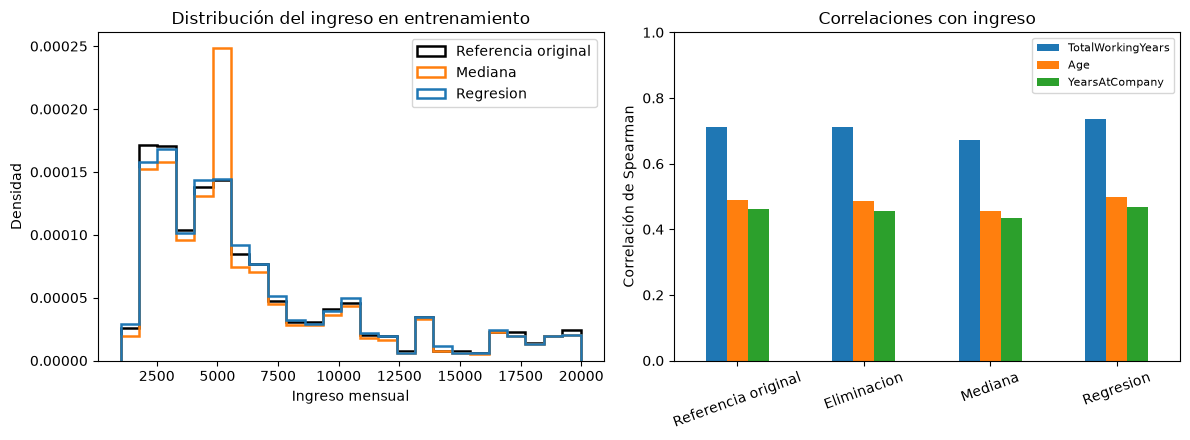

Comparación gráfica guardada.


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

colores = {
    "Referencia original": "black",
    "Mediana": "tab:orange",
    "Regresion": "tab:blue",
}

bins = np.linspace(
    referencia_train["MonthlyIncome"].min(),
    max(
        referencia_train["MonthlyIncome"].max(),
        train_regresion["MonthlyIncome"].max(),
    ),
    26,
)

for nombre, color in colores.items():
    axes[0].hist(
        conjuntos_comparacion[nombre]["MonthlyIncome"],
        bins=bins,
        density=True,
        histtype="step",
        linewidth=1.8,
        color=color,
        label=nombre,
    )

axes[0].set(
    xlabel="Ingreso mensual",
    ylabel="Densidad",
    title="Distribución del ingreso en entrenamiento",
)
axes[0].legend()

comparacion_correlaciones.set_index("Estrategia")[
    PREDICTORES_IMPUTACION
].plot.bar(ax=axes[1])

axes[1].set(
    ylabel="Correlación de Spearman",
    xlabel="",
    title="Correlaciones con ingreso",
    ylim=(0, 1),
)
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(
    DIRECTORIO_S3 / "figuras" / "hernan_comparacion_imputacion.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("Comparación gráfica guardada.")

## 11. Insumos compartidos para el modelamiento logístico

Se exportaron las versiones de entrenamiento y prueba para eliminación,
mediana y regresión. Se selecciona regresión como estrategia principal,
manteniendo las alternativas para el análisis de sensibilidad.

Los archivos conservan las variables en sus unidades originales.
La codificación y estandarización del modelo logístico se ajustarán
exclusivamente con entrenamiento. EmployeeNumber es un identificador
y Attrition es la respuesta; ninguno debe incorporarse como predictor.

Durante la validación cruzada, la imputación y la estandarización deben
ajustarse nuevamente dentro de cada pliegue de entrenamiento. Utilizar
directamente datos transformados con todo el entrenamiento introduciría
información del pliegue de validación.

In [24]:
# Pesos balanceados calculados solo con entrenamiento.
y_train_base = train["Attrition"].map({"No": 0, "Yes": 1})
frecuencias = y_train_base.value_counts()

pesos_clase = {
    str(clase): float(len(y_train_base) / (2 * frecuencias[clase]))
    for clase in [0, 1]
}

configuracion_s3 = {
    "semilla": SEMILLA,
    "estrategia_principal": "regresion",
    "estrategias_comparacion": [
        "eliminacion",
        "mediana",
        "regresion",
    ],
    "variable_imputada": "MonthlyIncome",
    "predictores_imputacion": PREDICTORES_IMPUTACION,
    "mediana_entrenamiento": float(imputador_mediana.statistics_[0]),
    "predictores_logistica_base": [
        "OverTime",
        "MonthlyIncome",
        "YearsAtCompany",
        "JobSatisfaction",
    ],
    "objetivo": "Attrition",
    "codificacion_objetivo": {"No": 0, "Yes": 1},
    "pesos_balanceados_entrenamiento_principal": pesos_clase,
    "particion": "Formativa2/datos/particion_70_30.csv",
    "datos_MCAR": "Formativa2/datos/IBM_HR_MCAR.csv",
    "referencia_F2": {
        "recall": 4 / 71,
        "AUC": 0.7724210125618576,
        "umbral": 0.5,
    },
    "validacion": (
        "Ajustar imputacion, escalado, seleccion y pesos "
        "dentro del entrenamiento de cada pliegue."
    ),
}

(
    DIRECTORIO_S3 / "resultados" / "configuracion_s3.json"
).write_text(
    json.dumps(configuracion_s3, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

resumen_datos.to_csv(
    DIRECTORIO_S3 / "resultados" / "hernan_particion_recuperada.csv",
    index=False,
)

print("Estrategia principal: regresión.")
print("Pesos balanceados de entrenamiento:", pesos_clase)
print("Configuración compartida guardada.")

Estrategia principal: regresión.
Pesos balanceados de entrenamiento: {'0': 0.5961761297798378, '1': 3.0993975903614457}
Configuración compartida guardada.
